# QASP quantum classifiers — sklearn validation suite

This notebook is an executable integration test for the `qasp.classifiers`
module. It deliberately covers both classifier readout families, every Born
class decoder, all bundled objectives, and four familiar sklearn datasets.

Coverage:

- **Breast Cancer Wisconsin** — averaged-observable binary classifier + MSE
- **Iris (grouped expectations)** — one observable group per class + categorical cross entropy
- **Iris** — 3-class Born classifier + parity decoder + categorical cross entropy
- **Wine** — 3-class Born classifier + contiguous decoder + categorical cross entropy
- **Digits (0–3)** — 4-class Born classifier + majority decoder + categorical cross entropy
- decoder conservation, gradient, probability-normalization, confusion-matrix,
  and QASP-versus-sklearn metric assertions

The samples and epoch counts are intentionally modest so the complete notebook
remains practical on `default.qubit`. Increase `EPOCHS` and
`TRAIN_PER_CLASS` for an accuracy-oriented experiment.

In [1]:
from pathlib import Path
import shutil
import subprocess
import sys

repo_root = Path.cwd()
if not (repo_root / "qasp").exists() and (repo_root.parent / "qasp").exists():
    repo_root = repo_root.parent
if not (repo_root / "qasp").exists():
    raise RuntimeError("Run this notebook from the QASP repository or examples directory.")
sys.path.insert(0, str(repo_root))

import matplotlib.pyplot as plt
import numpy as np
import torch
from IPython.display import Code, Image, IFrame, display
from sklearn.datasets import load_breast_cancer, load_digits, load_iris, load_wine
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score as sklearn_accuracy
from sklearn.metrics import average_precision_score as sklearn_average_precision
from sklearn.metrics import confusion_matrix as sklearn_confusion_matrix
from sklearn.metrics import f1_score as sklearn_f1
from sklearn.metrics import roc_auc_score as sklearn_roc_auc
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, MinMaxScaler, StandardScaler

from qasp import (
    ClassProbabilityDecoder,
    ClassifierTrainer,
    binary_cross_entropy,
    categorical_cross_entropy,
    classification_metrics,
    create_classifier,
    draw_classifier,
    hinge_loss,
    mean_squared_error,
    pr_auc_score,
    roc_auc_score,
)

SEED = 17
N_QUBITS = 4
EPOCHS = 20
TRAIN_PER_CLASS = 12
TEST_PER_CLASS = 6
torch.manual_seed(SEED)
np.random.seed(SEED)
print(f"QASP root: {repo_root}")
print(f"torch={torch.__version__}; qubits={N_QUBITS}; epochs={EPOCHS}")

QASP root: /Users/andresequeira/Desktop/QASP
torch=2.7.0; qubits=4; epochs=20


In [2]:
def display_tikz(tikz, name, width=1600, show_source=False):
    """Save standalone Quantikz, compile it, and display it in Jupyter."""
    output_dir = repo_root / "examples" / "tikz_output"
    output_dir.mkdir(exist_ok=True)

    tex_path = output_dir / f"{name}.tex"
    pdf_path = output_dir / f"{name}.pdf"
    png_path = output_dir / f"{name}.png"
    tex_path.write_text(tikz, encoding="utf-8")

    if show_source:
        display(Code(tikz, language="latex"))

    pdflatex = shutil.which("pdflatex")
    if pdflatex is None:
        print(f"Saved {tex_path}. Install a TeX distribution to render it.")
        return {"tex": tex_path}

    completed = subprocess.run(
        [pdflatex, "-interaction=nonstopmode", "-halt-on-error", tex_path.name],
        cwd=output_dir,
        capture_output=True,
        text=True,
    )
    if completed.returncode != 0:
        print(completed.stdout[-4000:])
        raise RuntimeError(f"LaTeX compilation failed for {tex_path}")

    pdftoppm = shutil.which("pdftoppm")
    sips = shutil.which("sips")
    if pdftoppm is not None:
        subprocess.run(
            [pdftoppm, "-png", "-singlefile", "-r", "200", pdf_path.name, name],
            cwd=output_dir,
            check=True,
            capture_output=True,
            text=True,
        )
    elif sips is not None:
        subprocess.run(
            [
                sips,
                "-s",
                "format",
                "png",
                "-Z",
                str(width),
                pdf_path.name,
                "--out",
                png_path.name,
            ],
            cwd=output_dir,
            check=True,
            capture_output=True,
            text=True,
        )
    else:
        print(f"Saved {pdf_path}; no PDF-to-PNG converter was found.")
        display(IFrame(str(pdf_path), width="100%", height=450))
        return {"tex": tex_path, "pdf": pdf_path}

    display(Image(filename=str(png_path)))
    return {"tex": tex_path, "pdf": pdf_path, "png": png_path}


print("pdflatex:", shutil.which("pdflatex") or "not found")
print("PDF converter:", shutil.which("pdftoppm") or shutil.which("sips") or "not found")

pdflatex: /opt/homebrew/bin/pdflatex
PDF converter: /Users/andresequeira/.cache/codex-runtimes/codex-primary-runtime/dependencies/bin/override/pdftoppm


## 1. Decoder integrity

Each decoder must conserve total Born probability. The table also makes the
basis-state allocation visible, including the modulo behavior for a non-power-
of-two class count.

In [3]:
decoder_specs = {
    "contiguous": dict(n_classes=3, n_measured_qubits=4),
    "parity": dict(n_classes=3, n_measured_qubits=4),
    "majority": dict(
        n_classes=4,
        n_measured_qubits=4,
        majority_blocks=((0, 1, 2), (3,)),
    ),
}

for name, kwargs in decoder_specs.items():
    decoder = ClassProbabilityDecoder(name, **kwargs)
    basis_probabilities = torch.rand(5, 2 ** kwargs["n_measured_qubits"])
    basis_probabilities = basis_probabilities / basis_probabilities.sum(-1, keepdim=True)
    class_probabilities = decoder(basis_probabilities)
    torch.testing.assert_close(
        class_probabilities.sum(-1), torch.ones(5), atol=1e-6, rtol=0
    )
    counts = torch.bincount(decoder.class_index, minlength=kwargs["n_classes"])
    print(
        f"{name:10s} class counts={counts.tolist()} "
        f"prior={decoder.reference_class_prior.tolist()} "
        f"map={decoder.class_index.tolist()}"
    )

print("All decoder conservation assertions passed.")

contiguous class counts=[6, 5, 5] prior=[0.375, 0.3125, 0.3125] map=[0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2]
parity     class counts=[8, 4, 4] prior=[0.5, 0.25, 0.25] map=[0, 2, 0, 1, 0, 1, 0, 2, 0, 1, 0, 2, 0, 2, 0, 1]
majority   class counts=[4, 4, 4, 4] prior=[0.25, 0.25, 0.25, 0.25] map=[0, 1, 0, 1, 0, 1, 2, 3, 0, 1, 2, 3, 2, 3, 2, 3]
All decoder conservation assertions passed.


## 2. Objective-function gradient checks

The loss tests use both scalar binary scores and normalized class
probabilities. Every objective must return a finite scalar and a finite
gradient.

In [4]:
binary_scores = torch.tensor([-0.7, 0.6], requires_grad=True)
binary_targets = torch.tensor([0, 1])
binary_probabilities = torch.tensor(
    [[0.85, 0.15], [0.25, 0.75]], requires_grad=True
)
multiclass_probabilities = torch.tensor(
    [[0.70, 0.20, 0.10], [0.10, 0.25, 0.65]], requires_grad=True
)
multiclass_targets = torch.tensor([0, 2])

loss_checks = {
    "mse": mean_squared_error(binary_scores, binary_targets),
    "hinge": hinge_loss(binary_scores, binary_targets),
    "binary_cross_entropy": binary_cross_entropy(binary_probabilities, binary_targets),
    "categorical_cross_entropy": categorical_cross_entropy(
        multiclass_probabilities, multiclass_targets
    ),
}
sum(loss_checks.values()).backward()
assert all(torch.isfinite(value) for value in loss_checks.values())
assert torch.isfinite(binary_scores.grad).all()
assert torch.isfinite(binary_probabilities.grad).all()
assert torch.isfinite(multiclass_probabilities.grad).all()
for name, value in loss_checks.items():
    print(f"{name:28s} {float(value.detach()):.6f}")
print("All objective gradient assertions passed.")

mse                          0.125000
hinge                        0.350000
binary_cross_entropy         0.225101
categorical_cross_entropy    0.393729
All objective gradient assertions passed.


## 3. Shared sklearn preprocessing and QASP configuration

Every dataset is stratified, standardized, compressed to four principal
components, then mapped into an angle-friendly interval. Label encoding always
produces the contiguous integers required by discrete classification losses.

The `Iris Grouped Exp` case demonstrates multiclass expectation readout. Its
nested `observables` list contains one nonempty group per class. QASP measures
all eight observables, averages within each group to form the three class
scores, and applies temperature-softmax. A flat list of three observables would
be the backward-compatible singleton-group case.

In [5]:
def prepare_dataset(loader, *, selected_classes=None):
    dataset = loader()
    X = np.asarray(dataset.data, dtype=np.float64)
    y = np.asarray(dataset.target)
    if selected_classes is not None:
        keep = np.isin(y, selected_classes)
        X, y = X[keep], y[keep]

    y = LabelEncoder().fit_transform(y)
    n_classes = int(np.unique(y).size)
    train_size = TRAIN_PER_CLASS * n_classes
    test_size = TEST_PER_CLASS * n_classes
    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        train_size=train_size,
        test_size=test_size,
        stratify=y,
        random_state=SEED,
    )

    standardizer = StandardScaler().fit(X_train)
    X_train_std = standardizer.transform(X_train)
    X_test_std = standardizer.transform(X_test)
    pca = PCA(n_components=N_QUBITS, random_state=SEED).fit(X_train_std)
    X_train_pca = pca.transform(X_train_std)
    X_test_pca = pca.transform(X_test_std)
    angle_scaler = MinMaxScaler(feature_range=(-np.pi / 2, np.pi / 2)).fit(X_train_pca)
    X_train = angle_scaler.transform(X_train_pca).astype("float32")
    X_test = angle_scaler.transform(X_test_pca).astype("float32")
    return X_train, X_test, y_train, y_test, n_classes, float(pca.explained_variance_ratio_.sum())


def classifier_config(
    readout,
    decoder=None,
    *,
    majority_blocks=None,
    observable=None,
    observables=None,
    temperature=1.0,
):
    config = {
        "feature_map": "AngleEmbedding",
        "feature_map_config": {
            "rotations": "Y",
            "input_scaling": False,
        },
        "ansatz": "AngleAnsatz",
        "ansatz_config": {
            "n_layers": 2,
            "rotations": "Y",
            "include_imprimitive": True,
            "include_final_imprimitive": True,
            "imprimitive_pattern": "ring",
            "reuploading": True,
        },
        "readout": readout,
        "init": "small_normal",
        "device": "default.qubit",
        "diff_method": "backprop",
        "temperature": temperature,
    }
    if decoder is not None:
        config["decoder"] = decoder
    if majority_blocks is not None:
        config["majority_blocks"] = majority_blocks
    if observable is not None:
        config["observable"] = observable
    if observables is not None:
        config["observables"] = observables
    return config


cases = [
    {
        "name": "Breast Cancer MSE",
        "loader": load_breast_cancer,
        "selected_classes": None,
        "readout": "expectation",
        "observable": ["Z 0", "ZZ 0 1", "X 1"],
        "objective": "mean_squared_error",
    },
    {
        "name": "Iris Grouped Exp",
        "loader": load_iris,
        "selected_classes": None,
        "readout": "expectation",
        "observables": [
            ["Z 0", "X 0", "ZZ 0 1"],
            ["Z 1", "X 1"],
            ["Z 2", "X 2", "ZZ 2 3"],
        ],
        "temperature": 0.8,
        "objective": "categorical_cross_entropy",
    },
    {
        "name": "Iris",
        "loader": load_iris,
        "selected_classes": None,
        "readout": "probabilities",
        "decoder": "parity",
        "objective": "categorical_cross_entropy",
    },
    {
        "name": "Wine",
        "loader": load_wine,
        "selected_classes": None,
        "readout": "probabilities",
        "decoder": "contiguous",
        "objective": "categorical_cross_entropy",
    },
    {
        "name": "Digits 0–3",
        "loader": load_digits,
        "selected_classes": [0, 1, 2, 3],
        "readout": "probabilities",
        "decoder": "majority",
        "objective": "categorical_cross_entropy",
    },
]
print("Prepared", len(cases), "dataset/readout configurations.")

Prepared 5 dataset/readout configurations.


## 4. End-to-end training and cross-library metric assertions

For each dataset this cell constructs a fresh QASP circuit, checks its output
contract, checks an actual quantum-parameter gradient, trains, evaluates, and
then compares QASP's accuracy/F1/confusion matrix against sklearn.

In [6]:
results = []
histories = {}
confusions = {}
trained_models = {}

for case_index, case in enumerate(cases):
    torch.manual_seed(SEED + case_index)
    prepared = prepare_dataset(
        case["loader"], selected_classes=case.get("selected_classes")
    )
    X_train, X_test, y_train, y_test, n_classes, explained_variance = prepared
    config = classifier_config(
        case["readout"],
        case.get("decoder"),
        majority_blocks=case.get("majority_blocks"),
        observable=case.get("observable"),
        observables=case.get("observables"),
        temperature=case.get("temperature", 1.0),
    )
    model = create_classifier(config, n_qubits=N_QUBITS, n_classes=n_classes)

    X_train_t = torch.tensor(X_train)
    y_train_t = torch.tensor(y_train, dtype=torch.long)
    X_test_t = torch.tensor(X_test)

    # Output contract and differentiability before optimization.
    initial_probabilities = model.predict_proba(X_train_t[:5])
    assert initial_probabilities.shape == (5, n_classes)
    torch.testing.assert_close(
        initial_probabilities.sum(-1), torch.ones(5), atol=1e-6, rtol=0
    )
    gradient_probe = model.compute_loss(
        X_train_t[:5], y_train_t[:5], objective=case["objective"]
    )
    gradient_probe.backward()
    quantum_gradients = [parameter.grad for parameter in model.qlayer.parameters()]
    assert quantum_gradients and all(gradient is not None for gradient in quantum_gradients)
    assert all(torch.isfinite(gradient).all() for gradient in quantum_gradients)
    model.zero_grad(set_to_none=True)

    trainer = ClassifierTrainer(
        model,
        objective=case["objective"],
        learning_rate=0.06,
    )
    history = trainer.fit(
        X_train_t,
        y_train_t,
        epochs=EPOCHS,
        batch_size=len(y_train_t),
        shuffle=True,
        verbose=0,
    )
    evaluation = trainer.evaluate(X_test_t, torch.tensor(y_test))
    predictions = evaluation["predictions"].numpy()
    if case["readout"] == "expectation" and n_classes == 2:
        decision_scores = model(X_test_t).squeeze(-1)
        torch.testing.assert_close(
            evaluation["predictions"], (decision_scores > 0).long()
        )
        observable_values = model.expectation_values(X_test_t)
        torch.testing.assert_close(
            decision_scores, observable_values.mean(dim=-1)
        )
    elif case["readout"] == "expectation":
        raw_expectations = model.expectation_values(X_test_t)
        grouped_scores = []
        start = 0
        for group in model.observable_groups:
            stop = start + len(group)
            grouped_scores.append(raw_expectations[..., start:stop].mean(dim=-1))
            start = stop
        grouped_scores = torch.stack(grouped_scores, dim=-1)
        torch.testing.assert_close(model(X_test_t), grouped_scores)
        torch.testing.assert_close(
            evaluation["probabilities"],
            torch.softmax(grouped_scores / model.temperature, dim=-1),
        )

    sklearn_acc = sklearn_accuracy(y_test, predictions)
    sklearn_f1_macro = sklearn_f1(y_test, predictions, average="macro")
    sklearn_cm = sklearn_confusion_matrix(
        y_test, predictions, labels=np.arange(n_classes)
    )
    probability_array = evaluation["probabilities"].numpy()
    if n_classes == 2:
        sklearn_roc = sklearn_roc_auc(y_test, probability_array[:, 1])
        sklearn_pr = sklearn_average_precision(y_test, probability_array[:, 1])
    else:
        sklearn_roc = sklearn_roc_auc(
            y_test, probability_array, multi_class="ovr", average="macro"
        )
        sklearn_pr = sklearn_average_precision(
            np.eye(n_classes)[y_test], probability_array, average="macro"
        )
    np.testing.assert_allclose(evaluation["accuracy"], sklearn_acc, atol=1e-12)
    np.testing.assert_allclose(evaluation["f1_macro"], sklearn_f1_macro, atol=1e-12)
    np.testing.assert_allclose(evaluation["roc_auc"], sklearn_roc, atol=1e-12)
    np.testing.assert_allclose(evaluation["pr_auc"], sklearn_pr, atol=1e-12)
    np.testing.assert_array_equal(evaluation["confusion_matrix"].numpy(), sklearn_cm)
    assert np.isfinite(history["train_loss"]).all()

    histories[case["name"]] = history["train_loss"]
    confusions[case["name"]] = sklearn_cm
    trained_models[case["name"]] = model
    results.append(
        {
            "dataset": case["name"],
            "classes": n_classes,
            "readout": case["readout"],
            "decoder": case.get("decoder", "n/a"),
            "objective": case["objective"],
            "pca_variance": explained_variance,
            "initial_loss": history["train_loss"][0],
            "final_loss": history["train_loss"][-1],
            "accuracy": sklearn_acc,
            "f1_macro": sklearn_f1_macro,
            "roc_auc": sklearn_roc,
            "pr_auc": sklearn_pr,
        }
    )
    print(
        f"{case['name']:14s} | {case['readout']:13s} | "
        f"{case.get('decoder', 'n/a'):10s} | "
        f"loss {history['train_loss'][0]:.4f}->{history['train_loss'][-1]:.4f} | "
        f"acc={sklearn_acc:.3f} | macro-F1={sklearn_f1_macro:.3f} | "
        f"ROC={sklearn_roc:.3f} | PR={sklearn_pr:.3f}"
    )

print("All end-to-end and QASP-versus-sklearn assertions passed.")

Breast Cancer MSE | expectation   | n/a        | loss 1.5036->0.9927 | acc=0.417 | macro-F1=0.294 | ROC=0.250 | PR=0.579


Iris Grouped Exp | expectation   | n/a        | loss 1.3113->0.9602 | acc=0.556 | macro-F1=0.567 | ROC=0.741 | PR=0.699


Iris           | probabilities | parity     | loss 1.7871->1.0576 | acc=0.444 | macro-F1=0.372 | ROC=0.574 | PR=0.534


Wine           | probabilities | contiguous | loss 2.0856->1.1482 | acc=0.444 | macro-F1=0.431 | ROC=0.647 | PR=0.604


Digits 0–3     | probabilities | majority   | loss 2.7875->1.4914 | acc=0.375 | macro-F1=0.374 | ROC=0.604 | PR=0.440
All end-to-end and QASP-versus-sklearn assertions passed.


## 5. Summary diagnostics

These plots are diagnostic rather than acceptance thresholds: small quantum
models and tiny balanced subsets can have noisy accuracy, while the assertions
above verify API correctness, normalization, differentiation, and metric
agreement deterministically.

Dataset         C       Readout    Decoder  PCA var    Loss 0    Loss N  Accuracy  F1 macro  ROC AUC   PR AUC
-------------------------------------------------------------------------------------------------------------
Breast Cancer MSE  2   expectation        n/a    0.867    1.5036    0.9927     0.417     0.294    0.250    0.579
Iris Grouped Exp  3   expectation        n/a    1.000    1.3113    0.9602     0.556     0.567    0.741    0.699
Iris            3 probabilities     parity    1.000    1.7871    1.0576     0.444     0.372    0.574    0.534
Wine            3 probabilities contiguous    0.824    2.0856    1.1482     0.444     0.431    0.647    0.604
Digits 0–3      4 probabilities   majority    0.578    2.7875    1.4914     0.375     0.374    0.604    0.440


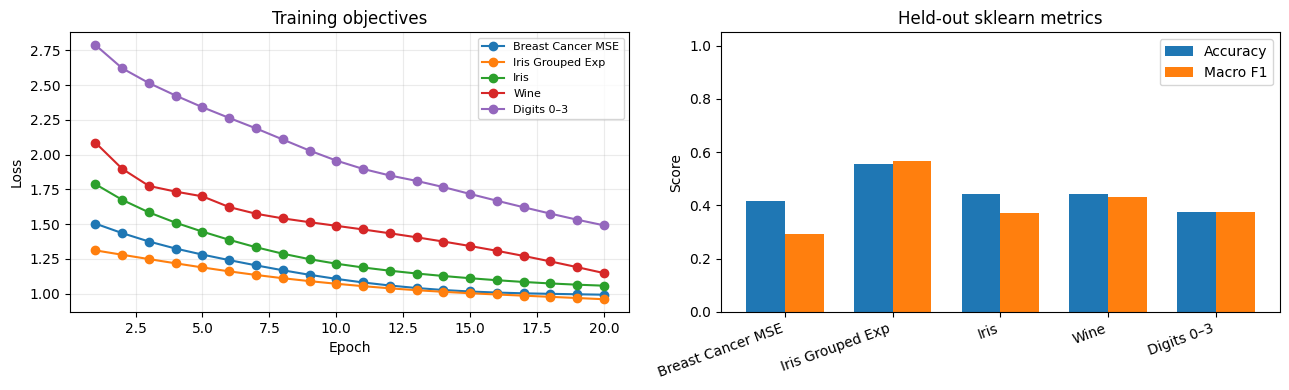

In [7]:
header = (
    f"{'Dataset':14s} {'C':>2s} {'Readout':>13s} {'Decoder':>10s} "
    f"{'PCA var':>8s} {'Loss 0':>9s} {'Loss N':>9s} {'Accuracy':>9s} "
    f"{'F1 macro':>9s} {'ROC AUC':>8s} {'PR AUC':>8s}"
)
print(header)
print("-" * len(header))
for result in results:
    print(
        f"{result['dataset']:14s} {result['classes']:2d} {result['readout']:>13s} "
        f"{result['decoder']:>10s} {result['pca_variance']:8.3f} "
        f"{result['initial_loss']:9.4f} {result['final_loss']:9.4f} "
        f"{result['accuracy']:9.3f} {result['f1_macro']:9.3f} "
        f"{result['roc_auc']:8.3f} {result['pr_auc']:8.3f}"
    )

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name, losses in histories.items():
    axes[0].plot(range(1, len(losses) + 1), losses, marker="o", label=name)
axes[0].set(title="Training objectives", xlabel="Epoch", ylabel="Loss")
axes[0].grid(alpha=0.25)
axes[0].legend(fontsize=8)

names = [result["dataset"] for result in results]
positions = np.arange(len(names))
axes[1].bar(positions - 0.18, [r["accuracy"] for r in results], width=0.36, label="Accuracy")
axes[1].bar(positions + 0.18, [r["f1_macro"] for r in results], width=0.36, label="Macro F1")
axes[1].set_xticks(positions, names, rotation=20, ha="right")
axes[1].set_ylim(0, 1.05)
axes[1].set(title="Held-out sklearn metrics", ylabel="Score")
axes[1].legend()
fig.tight_layout()
plt.show()

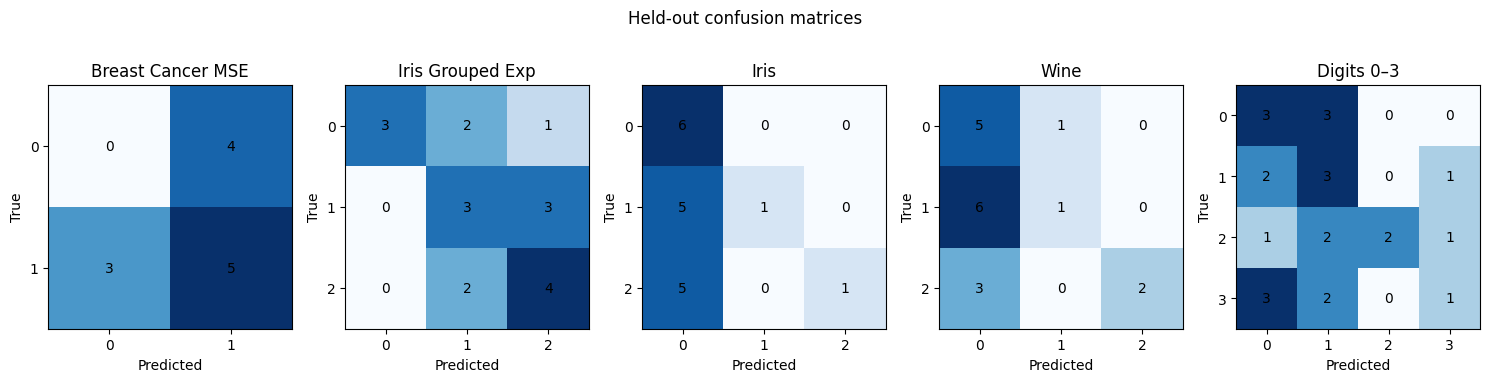

Notebook validation complete.


In [8]:
fig, axes = plt.subplots(1, len(results), figsize=(15, 3.5))
for axis, result in zip(axes, results):
    matrix = confusions[result["dataset"]]
    image = axis.imshow(matrix, cmap="Blues")
    for row in range(matrix.shape[0]):
        for column in range(matrix.shape[1]):
            axis.text(column, row, int(matrix[row, column]), ha="center", va="center")
    axis.set(
        title=result["dataset"],
        xlabel="Predicted",
        ylabel="True",
        xticks=range(matrix.shape[1]),
        yticks=range(matrix.shape[0]),
    )
fig.suptitle("Held-out confusion matrices", y=1.03)
fig.tight_layout()
plt.show()

print("Notebook validation complete.")

## 6. Classifier drawing and publication-ready TikZ

`draw_classifier` accepts either a trained classifier or the same configuration
used by `create_classifier`. As in QASP's kernel drawing notebook, the helper
below saves the standalone Quantikz source, compiles a vector PDF, creates a PNG
preview, and displays the rendered classifier circuit inline.

0: ─╭AngleEmbedding(M0)──RY(0.88)──╭●───────╭Z─╭AngleEmbedding(M0)──RY(-0.55)─╭●───────╭Z─┤ ···
1: ─├AngleEmbedding(M0)──RY(0.21)──╰Z─╭●────│──├AngleEmbedding(M0)──RY(-0.82)─╰Z─╭●────│──┤ ···
2: ─├AngleEmbedding(M0)──RY(0.79)─────╰Z─╭●─│──├AngleEmbedding(M0)──RY(0.73)─────╰Z─╭●─│──┤ ···
3: ─╰AngleEmbedding(M0)──RY(-1.07)───────╰Z─╰●─╰AngleEmbedding(M0)──RY(-0.15)───────╰Z─╰●─┤ ···

0: ···   <1.00*Z> ╭<1.00*Z@Z>          
1: ···            ╰<1.00*Z@Z>  <1.00*X>
2: ···                                 
3: ···                                 
M0 = 
tensor([-1.1368, -0.5767, -0.3363, -0.6403])


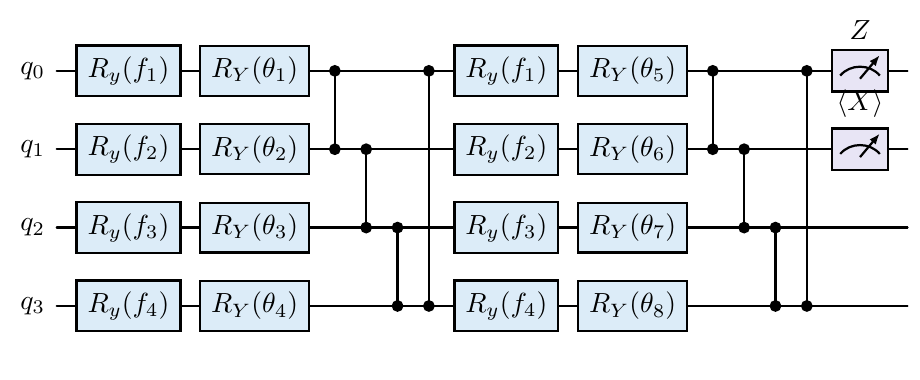

Generated standalone symbolic Quantikz source: 1709 characters
Classifier circuit artifacts: {'tex': PosixPath('/Users/andresequeira/Desktop/QASP/examples/tikz_output/classifier_expectation_mse.tex'), 'pdf': PosixPath('/Users/andresequeira/Desktop/QASP/examples/tikz_output/classifier_expectation_mse.pdf'), 'png': PosixPath('/Users/andresequeira/Desktop/QASP/examples/tikz_output/classifier_expectation_mse.png')}


In [9]:
mse_model = trained_models["Breast Cancer MSE"]
drawing_input = torch.tensor(prepare_dataset(load_breast_cancer)[1][0])
text_circuit = draw_classifier(mse_model, inputs=drawing_input, output="text")
paper_tikz = draw_classifier(
    mse_model,
    inputs=drawing_input,
    output="tikz",
    tikz_options={
        "standalone": True,
        "symbolic_parameters": True,
    },
)
assert "AngleEmbedding" in text_circuit
assert r"\documentclass" in paper_tikz
assert r"\begin{quantikz}" in paper_tikz
print(text_circuit)
classifier_figure = display_tikz(
    paper_tikz,
    "classifier_expectation_mse",
    show_source=False,
)
assert classifier_figure["tex"].exists()
if "pdf" in classifier_figure:
    assert classifier_figure["pdf"].exists()
if "png" in classifier_figure:
    assert classifier_figure["png"].exists()
print("Generated standalone symbolic Quantikz source:", len(paper_tikz), "characters")
print("Classifier circuit artifacts:", classifier_figure)

## 7. Explicit imbalanced-data AUC check

Accuracy can look excellent when only 5% of examples are positive. This final
test uses a deliberately imbalanced label distribution with tied scores and
checks QASP's threshold-independent ROC AUC and average-precision PR AUC
against sklearn exactly.

In [10]:
imbalanced_targets = torch.tensor([0] * 95 + [1] * 5)
negative_scores = torch.linspace(0.01, 0.75, 95)
positive_scores = torch.tensor([0.20, 0.55, 0.55, 0.80, 0.95])
imbalanced_scores = torch.cat((negative_scores, positive_scores))
imbalanced_probabilities = torch.stack(
    (1.0 - imbalanced_scores, imbalanced_scores), dim=1
)

qasp_roc = roc_auc_score(imbalanced_targets, imbalanced_probabilities)
qasp_pr = pr_auc_score(imbalanced_targets, imbalanced_probabilities)
sklearn_roc = sklearn_roc_auc(imbalanced_targets, imbalanced_scores)
sklearn_pr = sklearn_average_precision(imbalanced_targets, imbalanced_scores)
np.testing.assert_allclose(float(qasp_roc), sklearn_roc, atol=1e-12)
np.testing.assert_allclose(float(qasp_pr), sklearn_pr, atol=1e-12)

majority_accuracy = float((imbalanced_targets == 0).float().mean())
print(f"Positive prevalence: {float(imbalanced_targets.float().mean()):.3f}")
print(f"Always-negative accuracy: {majority_accuracy:.3f}")
print(f"QASP ROC AUC: {float(qasp_roc):.6f}")
print(f"QASP PR AUC / average precision: {float(qasp_pr):.6f}")
print("Imbalanced AUC values match sklearn exactly.")

Positive prevalence: 0.050
Always-negative accuracy: 0.950
QASP ROC AUC: 0.743158
QASP PR AUC / average precision: 0.466667
Imbalanced AUC values match sklearn exactly.


## 8. Differentiable Pauli propagation

Expectation-readout classifiers can select the same `lightning.pp` logical
backend as observable-based QASP policies. The following exact-mode check
disables every truncation and copies the trained grouped-expectation Iris model
into a Pauli-propagation classifier. It compares raw observable expectations,
class probabilities, categorical-cross-entropy loss, and every quantum
parameter gradient against `default.qubit`. The final optimizer step confirms
that `ClassifierTrainer` updates the circuit through the retained Pauli paths.

For approximate propagation, set `pp_truncation`, `pp_topM`, `pp_tau`, and
`pp_prune_every`; report those settings and compare against an exact reference.

In [11]:
grouped_case = next(case for case in cases if case["name"] == "Iris Grouped Exp")
X_pp_train, _, y_pp_train, _, _, _ = prepare_dataset(load_iris)
pp_inputs = torch.tensor(X_pp_train[:4])
pp_targets = torch.tensor(y_pp_train[:4], dtype=torch.long)

exact_model = trained_models["Iris Grouped Exp"]
pp_config = classifier_config(
    "expectation",
    observables=grouped_case["observables"],
    temperature=grouped_case["temperature"],
)
pp_config.update(
    device="lightning.pp",
    diff_method="backprop",
    pp_truncation=None,
    pp_topM=None,
    pp_tau=0.0,
    pp_prune=False,
)
pp_model = create_classifier(pp_config, n_qubits=N_QUBITS, n_classes=3)
pp_model.qlayer.load_state_dict(exact_model.qlayer.state_dict())

exact_model.zero_grad(set_to_none=True)
pp_model.zero_grad(set_to_none=True)
exact_raw = exact_model.expectation_values(pp_inputs)
pp_raw = pp_model.expectation_values(pp_inputs)
exact_probabilities = exact_model.predict_proba(pp_inputs)
pp_probabilities = pp_model.predict_proba(pp_inputs)
torch.testing.assert_close(pp_raw, exact_raw, atol=2e-6, rtol=2e-6)
torch.testing.assert_close(
    pp_probabilities, exact_probabilities, atol=2e-6, rtol=2e-6
)

exact_loss = exact_model.compute_loss(
    pp_inputs, pp_targets, objective="categorical_cross_entropy"
)
pp_loss = pp_model.compute_loss(
    pp_inputs, pp_targets, objective="categorical_cross_entropy"
)
exact_loss.backward()
pp_loss.backward()
torch.testing.assert_close(pp_loss, exact_loss, atol=2e-6, rtol=2e-6)
for exact_parameter, pp_parameter in zip(
    exact_model.qlayer.parameters(), pp_model.qlayer.parameters()
):
    torch.testing.assert_close(
        pp_parameter.grad, exact_parameter.grad, atol=2e-6, rtol=2e-6
    )

# Switch to an explicitly truncated configuration for the optimizer check.
pp_model.pp_truncation = 3
pp_model.pp_engine.topM = 20_000
pp_model.pp_engine.tau = 1e-10
pp_model.pp_engine.prune_every = 5
pp_model.pp_prune = True
before_update = [
    parameter.detach().clone() for parameter in pp_model.qlayer.parameters()
]
pp_trainer = ClassifierTrainer(
    pp_model,
    objective="categorical_cross_entropy",
    learning_rate=0.02,
)
pp_history = pp_trainer.fit(
    pp_inputs,
    pp_targets,
    epochs=2,
    batch_size=2,
    shuffle=False,
)
assert np.isfinite(pp_history["train_loss"]).all()
assert any(
    not torch.equal(before, after.detach())
    for before, after in zip(before_update, pp_model.qlayer.parameters())
)

print(f"Maximum exact-vs-PP expectation error: {float((exact_raw - pp_raw).abs().max()):.3e}")
print(f"Maximum exact-vs-PP probability error: {float((exact_probabilities - pp_probabilities).abs().max()):.3e}")
print(f"Exact loss={float(exact_loss):.8f}; PP loss={float(pp_loss):.8f}")
print("ClassifierTrainer updated the truncated differentiable PP model.")

Maximum exact-vs-PP expectation error: 2.384e-07
Maximum exact-vs-PP probability error: 5.960e-08
Exact loss=0.97882950; PP loss=0.97882950
ClassifierTrainer updated the truncated differentiable PP model.
